Scalarized fitness fuction with mean_perf - f1_std

In [10]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

# Project root
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [11]:
import sys
from pathlib import Path

# Find project root automatically
PROJECT_ROOT = Path.cwd().parents[1]

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


In [12]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode
from evolution.genetic_DT_GA import evolve_trees, _load_dataset_csv

In [13]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    scores = []

    for tr, te in skf.split(X, y):

        algo = decode(gene)
        algo.fit(X[tr], y[tr])

        m = evaluate_tree_new(algo, X[te], y[te])
        scores.append(m["f1"])

    return np.array(scores)

In [14]:
random.seed(42)

data_path = PROJECT_ROOT / "data"

# (15)
datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
}

# (5)
unseen_datasets = {
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

target_cols = {name: None for name in list(datasets.keys()) + list(unseen_datasets.keys())}

In [15]:
mu = 25
lambd = 25
generations = 30

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Training datasets:", list(datasets.keys()))

Starting Evolutionary Process...
Experiment with mu=25, lambda=25 for 30 generations.
Training datasets: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red']


In [7]:
timestamp = time.strftime("%Y%m%d_%H%M")

results_dir = Path(
    r"C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs"
)

results_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved in:", results_dir)

Figures will be saved in: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs


In [8]:
evo_t0 = time.time()

best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = evolve_trees(
    datasets,
    unseen_datasets,
    target_cols=target_cols,
    mu=mu,
    lambd=lambd,
    generations=generations)

evo_tf = time.time()


# Tiempo total
total_time = evo_tf - evo_t0
total_minutes = total_time / 60
total_hours = total_time / 3600

# Tiempo promedio por generación
time_per_gen = total_time / generations

print("\n ===== Evolution Summary =====")
print(f"Total time: {total_time:.2f} seconds")
print(f"Total time: {total_minutes:.2f} minutes")
print(f"Total time: {total_hours:.2f} hours")
print(f"Avg time per generation: {time_per_gen:.2f} seconds")

print("\n ===== Results =====")
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)


[Evaluation] 25 genes | 15 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[6, 4, 20, 2, 1, 0, 4, 10] fitness=0.0499 mean_f1=0.1958 f1_std=0.1459 total=323.21s pid=26740
  dataset mean F1 | best=0.4376 worst=0.0101 avg=0.1958
  dataset mean F1 values=[0.0101, 0.173, 0.0541, 0.072, 0.0667, 0.2059, 0.3662, 0.1397, 0.1405, 0.3906, 0.0183, 0.348, 0.3952, 0.4376, 0.1185]
  - abalone              F1 mean=0.0101 best=0.0110 worst=0.0090 folds=[0.0104, 0.011, 0.009, 0.0106, 0.0095]
    time total=0.36s decode=0.00s fit=0.26s metrics=0.08s | depth=0.00 nodes=1.00
  - anneal               F1 mean=0.1730 best=0.1730 worst=0.1729 folds=[0.173, 0.173, 0.173, 0.1729, 0.1729]
    time total=0.87s decode=0.00s fit=0.81s metrics=0.04s | depth=0.60 nodes=2.20
  - arrhythmia           F1 mean=0.0541 best=0.0542 worst=0.0539 folds=[0.0539, 0.0542]
    time total=2.51s decode=0.00s fit=2.46s metrics=0.02s | depth=0.00 nodes=1.00
  - bridges              F1 mean=0.0720 best=0.0859

In [9]:
# Report generalization across datasets
for name, dataset_path in datasets.items():
    target_col = None if target_cols is None else target_cols.get(name, None)

    X, y = _load_dataset_csv(dataset_path, target_col=target_col)
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)

    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


abalone: mean F1=0.1152, std F1=0.0141, folds=[0.0993347  0.1214121  0.12153372 0.13498255 0.09886048]
anneal: mean F1=0.9425, std F1=0.0756, folds=[0.79918367 0.98782079 0.93251701 1.         0.99311635]


c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes

arrhythmia: mean F1=0.3656, std F1=0.0237, folds=[0.32923808 0.36445612 0.35203467 0.39119424 0.39104546]


c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


bridges: mean F1=0.4577, std F1=0.1081, folds=[0.35614246 0.48021978 0.45396825 0.35034014 0.64761905]
balance_scale: mean F1=0.1187, std F1=0.0145, folds=[0.13706941 0.12640586 0.10506061 0.09834236 0.12641268]
car: mean F1=0.9425, std F1=0.0264, folds=[0.95193946 0.89895563 0.94810253 0.97977245 0.93376469]
cylinder_bands: mean F1=0.7258, std F1=0.0399, folds=[0.70567033 0.78023534 0.76511527 0.67619048 0.70168404]
glass: mean F1=0.6065, std F1=0.1112, folds=[0.3984127  0.63105735 0.73435245 0.63524531 0.63319531]
heart_disease: mean F1=0.2542, std F1=0.0717, folds=[0.17246377 0.19174603 0.37443182 0.25322793 0.27936508]
ionosphere: mean F1=0.9007, std F1=0.0278, folds=[0.89093702 0.9228905  0.89204671 0.93881119 0.85871272]
semeion: mean F1=0.7228, std F1=0.0290, folds=[0.72646721 0.71461991 0.73820172 0.67356226 0.76096445]
sonar: mean F1=0.7114, std F1=0.1143, folds=[0.71167048 0.76136364 0.87755102 0.67987988 0.52644377]
tic_tac_toe: mean F1=0.8622, std F1=0.0443, folds=[0.864262

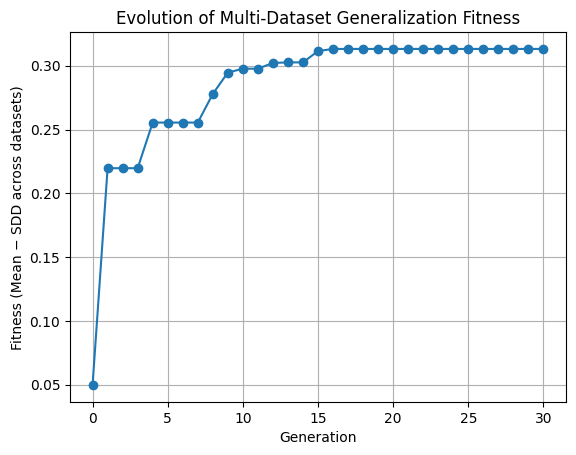

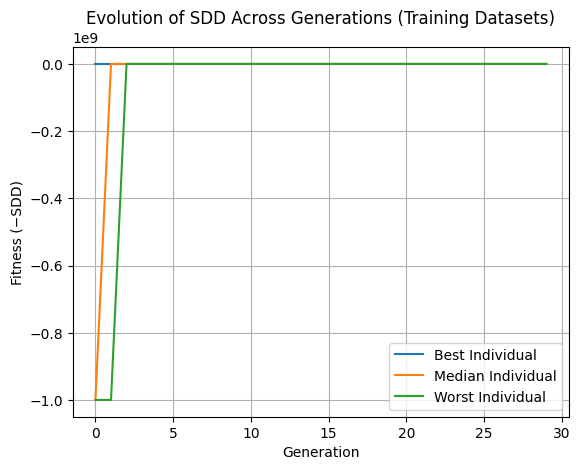

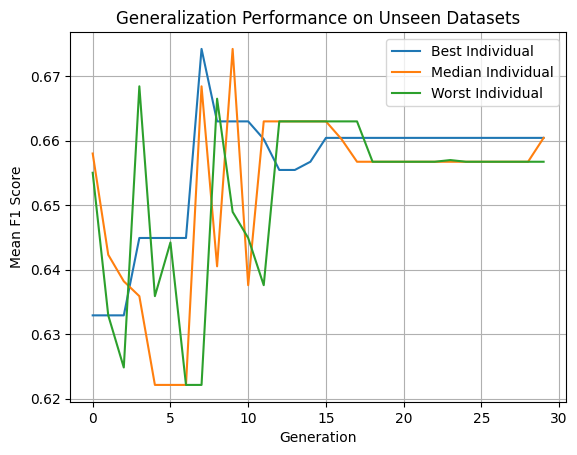

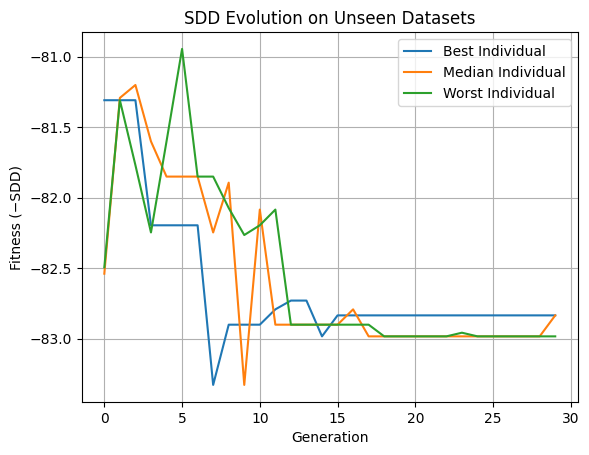

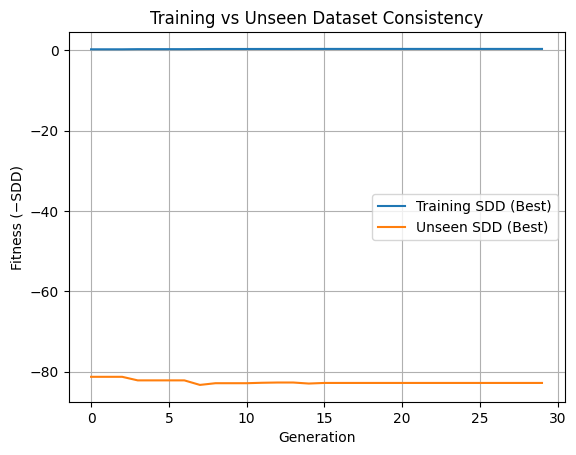

In [ ]:
# Graph 1 — Best Fitness Evolution
fig = plt.figure()

plt.plot(history, marker="o")

plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "fitness_evolution.png", dpi=300)



# Graph 2 — Training SDD Evolution
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Best Individual")
plt.plot(fitness_rank_history["median"], label="Median Individual")
plt.plot(fitness_rank_history["worst"], label="Worst Individual")

plt.title("Evolution of SDD Across Generations (Training Datasets)")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_sdd.png", dpi=300)



# Graph 3 — Generalization F1
fig = plt.figure()

plt.plot(generalization_history["best"], label="Best Individual")
plt.plot(generalization_history["median"], label="Median Individual")
plt.plot(generalization_history["worst"], label="Worst Individual")

plt.title("Generalization Performance on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Mean F1 Score")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "generalization_f1.png", dpi=300)



# Graph 4 — Unseen Dataset SDD
fig = plt.figure()

plt.plot(generalization_sdd_history["best"], label="Best Individual")
plt.plot(generalization_sdd_history["median"], label="Median Individual")
plt.plot(generalization_sdd_history["worst"], label="Worst Individual")

plt.title("SDD Evolution on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)

#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "unseen_sdd.png", dpi=300)



# Graph 5 — Training vs Unseen SDD
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Training SDD (Best)")
plt.plot(generalization_sdd_history["best"], label="Unseen SDD (Best)")

plt.title("Training vs Unseen Dataset Consistency")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_vs_unseen_sdd.png", dpi=300)

plt.show()

Winning genomes for each experiment 

In [9]:
import numpy as np
import pandas as pd

from evolution.genetic_DT_GA import (
    _eval_one_algo_all_datasets,
    _fitness_from_dataset_scores,
)

def safe_xi(score, best=1.0, eps=1e-8):
    return abs(score - best) / (((score + best) / 2) + eps)

# ---- Put your winning genomes here ----
WINNING_GENES = {
    "mean_minus_sdd": [1, 1, 9, 1, 1, 1, 2, 3],
    "minus_sdd": [6, 3, 4, 2, 2, 0, 0, 3],
}

k_folds = 5
seed = 42
timeout_s = None

datasets_info = []
for ds_name, ds_path in datasets.items():
    target_col = None if "target_cols" not in globals() else target_cols.get(ds_name, None)
    datasets_info.append((ds_name, str(ds_path), target_col))

dataset_split_seeds = {
    ds_name: abs(hash((seed, ds_name))) % (2**31 - 1)
    for ds_name in datasets.keys()
}

summary_rows = []
detail_rows = []

for exp_name, gene in WINNING_GENES.items():
    print(f"\n===== FINAL EVALUATION: {exp_name} =====")
    print(f"Gene: {gene}")

    out = _eval_one_algo_all_datasets(
        algo_genome=gene,
        datasets_info=datasets_info,
        n_splits=k_folds,
        dataset_split_seeds=dataset_split_seeds,
        bad_score=0.0,
        timeout_s=timeout_s,
    )

    scores_by_dataset = out["results"]

    dataset_mean_f1 = {
        ds: float(np.mean(scores))
        for ds, scores in scores_by_dataset.items()
    }

    dataset_f1_scores = np.array(list(dataset_mean_f1.values()), dtype=float)

    mean_f1 = float(np.mean(dataset_f1_scores))

    # New SDD: percentage differences using best dataset F1 for this genome
    best_dataset_f1 = float(np.max(dataset_f1_scores))

    xi = np.abs(dataset_f1_scores - best_dataset_f1) / (
        (dataset_f1_scores + best_dataset_f1) / 2 + 1e-8
    )

    SDD = float(np.std(xi))
    raw_std_across_datasets = float(np.std(dataset_f1_scores))

    fitness_mean_minus_sdd = mean_f1 - SDD
    fitness_minus_sdd = -SDD

    # Old SDD from the previous -SDD experiment:
    # xi_i = relative difference between dataset mean F1 and ideal best = 1.0
    old_xi_values = np.array([safe_xi(score, best=1.0) for score in dataset_f1_scores], dtype=float)

    if len(old_xi_values) <= 1:
        old_xi_sdd = 0.0
    else:
        old_xi_sdd = float(np.std(old_xi_values, ddof=1))

    old_fitness_minus_sdd = -old_xi_sdd

    print(f"Mean F1: {mean_f1:.6f}")
    print(f"New SDD across datasets: {SDD:.6f}")
    print(f"New Fitness mean - SDD: {fitness_mean_minus_sdd:.6f}")
    print(f"New Fitness -SDD: {fitness_minus_sdd:.6f}")
    print(f"Raw std F1 across datasets: {raw_std_across_datasets:.6f}")
    print(f"Old xi-based SDD: {old_xi_sdd:.6f}")
    print(f"Old Fitness -SDD: {old_fitness_minus_sdd:.6f}")

    summary_rows.append({
        "experiment": exp_name,
        "gene": gene,
        "mean_f1": mean_f1,

        "new_SDD": SDD,
        "new_fitness_mean_minus_SDD": fitness_mean_minus_sdd,
        "new_fitness_minus_SDD": fitness_minus_sdd,

        "raw_std_f1_across_datasets": raw_std_across_datasets,

        "old_xi_based_SDD": old_xi_sdd,
        "old_fitness_minus_SDD": old_fitness_minus_sdd,
        "old_xi_values": old_xi_values.tolist(),

        "infeasible": out["infeasible"],
        "failed_dataset": out["failed_dataset"],
        "failure_reason": out["failure_reason"],
    })

    for ds, scores in scores_by_dataset.items():
        times = out["times"][ds]
        struct = out["structures"][ds]

        mean_ds_f1 = float(np.mean(scores))
        old_ds_xi = safe_xi(mean_ds_f1, best=1.0)

        detail_rows.append({
            "experiment": exp_name,
            "dataset": ds,
            "mean_f1": mean_ds_f1,
            "std_f1_folds": float(np.std(scores)),
            "best_fold_f1": float(np.max(scores)),
            "worst_fold_f1": float(np.min(scores)),
            "old_xi_distance_from_1": old_ds_xi,
            "fold_scores": scores,
            "total_time_s": times["total"],
            "fit_time_s": times["fit"],
            "mean_depth": struct["depth"],
            "mean_nodes": struct["nodes"],
        })

summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(detail_rows)

display(summary_df)
display(details_df.sort_values(["experiment", "mean_f1"], ascending=[True, False]))


===== FINAL EVALUATION: mean_minus_sdd =====
Gene: [1, 1, 9, 1, 1, 1, 2, 3]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1: 0.581320
New SDD across datasets: 0.544853
New Fitness mean - SDD: 0.036466
New Fitness -SDD: -0.544853
Raw std F1 across datasets: 0.294790
Old xi-based SDD: 0.549584
Old Fitness -SDD: -0.549584

===== FINAL EVALUATION: minus_sdd =====
Gene: [6, 3, 4, 2, 2, 0, 0, 3]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1: 0.184941
New SDD across datasets: 0.633195
New Fitness mean - SDD: -0.448254
New Fitness -SDD: -0.633195
Raw std F1 across datasets: 0.132817
Old xi-based SDD: 0.384641
Old Fitness -SDD: -0.384641


,experiment,gene,mean_f1,new_SDD,new_fitness_mean_minus_SDD,new_fitness_minus_SDD,raw_std_f1_across_datasets,old_xi_based_SDD,old_fitness_minus_SDD,old_xi_values,infeasible,failed_dataset,failure_reason
0,mean_minus_sdd,"[1, 1, 9, 1, 1, 1, 2, 3]",0.581320,0.544853,0.036466,-0.544853,0.294790,0.549584,-0.549584,"[1.6519216100713408, 0.06838017244401255, 1.01...",False,None,None
1,minus_sdd,"[6, 3, 4, 2, 2, 0, 0, 3]",0.184941,0.633195,-0.448254,-0.633195,0.132817,0.384641,-0.384641,"[1.9599869598131494, 1.4101391801187955, 1.794...",False,None,None


,experiment,dataset,mean_f1,std_f1_folds,best_fold_f1,worst_fold_f1,old_xi_distance_from_1,fold_scores,total_time_s,fit_time_s,mean_depth,mean_nodes
13,mean_minus_sdd,breast_cancer,0.934141,0.024150,0.962660,0.904302,0.068101,"[0.9066491975106452, 0.9531057178116001, 0.943...",9.165207,9.097868,11.0,133.8
1,mean_minus_sdd,anneal,0.933880,0.073648,0.993469,0.792955,0.068380,"[0.993469387755102, 0.7929552503322995, 0.9632...",3.306885,3.217315,10.4,43.4
5,mean_minus_sdd,car,0.921132,0.023025,0.947051,0.884619,0.082106,"[0.9273609639792494, 0.884619322119322, 0.9405...",5.395788,5.280758,11.0,192.2
9,mean_minus_sdd,ionosphere,0.884452,0.009653,0.900568,0.875556,0.122633,"[0.8804713804713804, 0.9005681818181819, 0.890...",17.531782,17.387631,11.0,78.2
12,mean_minus_sdd,tic_tac_toe,0.838562,0.015705,0.868630,0.825341,0.175613,"[0.8686300758589915, 0.8354561305003103, 0.825...",7.949770,7.873048,11.0,357.0
10,mean_minus_sdd,semeion,0.732516,0.023138,0.762221,0.694011,0.308781,"[0.7622212449959573, 0.6940113838775407, 0.723...",833.758201,833.582061,11.0,504.6
6,mean_minus_sdd,cylinder_bands,0.722105,0.041907,0.780235,0.660970,0.322739,"[0.6967116586647342, 0.7538569424964936, 0.780...",30.523936,30.382498,11.0,162.2
11,mean_minus_sdd,sonar,0.715144,0.036614,0.761364,0.665909,0.332166,"[0.6659090909090909, 0.7613636363636364, 0.688...",14.811086,14.743375,11.0,107.8
7,mean_minus_sdd,glass,0.536475,0.074504,0.629901,0.449245,0.603362,"[0.47945960849186653, 0.449244655127008, 0.620...",8.466537,8.388708,11.0,175.8
3,mean_minus_sdd,bridges,0.358152,0.062353,0.470238,0.284127,0.945178,"[0.325, 0.2841269841269841, 0.34375, 0.4702380...",4.835996,4.781554,11.0,113.0


In [16]:
import numpy as np
import pandas as pd

from evolution.genetic_DT_GA import _eval_one_algo_all_datasets


# ---- Winning genomes ----
WINNING_GENES = {
    "mean_minus_sdd": [1, 1, 9, 1, 1, 1, 2, 3],
    "minus_sdd": [6, 3, 4, 2, 2, 0, 0, 3],
}

k_folds = 5
seed = 42
timeout_s = None


def compute_clean_metrics(scores_by_dataset):
    """
    Computes final report metrics:
    1. Mean F1 across datasets
    2. SDD across datasets, using the old xi-based definition
    3. Raw standard deviation of dataset mean F1
    4. Fitness = Mean(F1) - SDD, where SDD is raw std of F1
       exactly like _fitness_from_dataset_scores
    """

    dataset_mean_f1_values = []

    for scores in scores_by_dataset.values():
        clean_scores = [float(s) for s in scores if np.isfinite(s)]
        mean_f1 = float(np.mean(clean_scores)) if clean_scores else 0.0
        dataset_mean_f1_values.append(mean_f1)

    dataset_mean_f1_values = np.array(dataset_mean_f1_values, dtype=float)

    if len(dataset_mean_f1_values) == 0:
        return -np.inf, np.inf, np.inf, -np.inf, []

    # 1. Mean F1 across datasets
    mean_f1 = float(np.mean(dataset_mean_f1_values))

    # 2. SDD across datasets: old xi-based SDD
    xi_values = np.abs(dataset_mean_f1_values - 1.0) / (
        ((dataset_mean_f1_values + 1.0) / 2) + 1e-8
    )

    sdd_across_datasets = (
        float(np.std(xi_values, ddof=1))
        if len(xi_values) > 1
        else 0.0
    )

    old_fitness_minus_sdd = -sdd_across_datasets

    # 3. Raw standard deviation of F1
    raw_std_f1 = float(np.std(dataset_mean_f1_values))

    # 4. Fitness exactly as in your current function:
    # Mean(F1) - std(dataset_mean_f1_values)
    fitness_mean_f1_minus_std = mean_f1 - raw_std_f1

    return (
        mean_f1,
        old_fitness_minus_sdd,
        raw_std_f1,
        fitness_mean_f1_minus_std,
        dataset_mean_f1_values.tolist(),
    )


datasets_info = []
for ds_name, ds_path in datasets.items():
    target_col = None if "target_cols" not in globals() else target_cols.get(ds_name, None)
    datasets_info.append((ds_name, str(ds_path), target_col))


dataset_split_seeds = {
    ds_name: abs(hash((seed, ds_name))) % (2**31 - 1)
    for ds_name in datasets.keys()
}


summary_rows = []
detail_rows = []


for exp_name, gene in WINNING_GENES.items():
    print(f"\n===== FINAL EVALUATION: {exp_name} =====")
    print(f"Gene: {gene}")

    out = _eval_one_algo_all_datasets(
        algo_genome=gene,
        datasets_info=datasets_info,
        n_splits=k_folds,
        dataset_split_seeds=dataset_split_seeds,
        bad_score=0.0,
        timeout_s=timeout_s,
    )

    scores_by_dataset = out["results"]

    (
        mean_f1,
        old_fitness_minus_sdd,
        raw_std_f1,
        fitness_mean_f1_minus_sdd,
        dataset_mean_f1_values,
    ) = compute_clean_metrics(scores_by_dataset)

    print(f"Mean F1 across datasets: {mean_f1:.6f}")
    print(f"SDD across datasets / Old Fitness -SDD: {old_fitness_minus_sdd:.6f}")
    print(f"Raw standard deviation of F1: {raw_std_f1:.6f}")
    print(f"Fitness Mean(F1) - SDD: {fitness_mean_f1_minus_sdd:.6f}")

    summary_rows.append({
        "experiment": exp_name,
        "gene": gene,
        "mean_f1_across_datasets": mean_f1,
        "old_fitness_minus_sdd": old_fitness_minus_sdd,
        "raw_std_f1_across_datasets": raw_std_f1,
        "fitness_mean_f1_minus_sdd": fitness_mean_f1_minus_sdd,
        "dataset_mean_f1_values": dataset_mean_f1_values,
        "infeasible": out["infeasible"],
        "failed_dataset": out["failed_dataset"],
        "failure_reason": out["failure_reason"],
    })

    for ds, scores in scores_by_dataset.items():
        clean_scores = [float(s) for s in scores if np.isfinite(s)]

        detail_rows.append({
            "experiment": exp_name,
            "dataset": ds,
            "mean_f1": float(np.mean(clean_scores)) if clean_scores else 0.0,
            "std_f1_folds": float(np.std(clean_scores)) if clean_scores else 0.0,
            "fold_scores": clean_scores,
        })


summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(detail_rows)

display(summary_df)
display(details_df.sort_values(
    ["experiment", "mean_f1"],
    ascending=[True, False]
))


===== FINAL EVALUATION: mean_minus_sdd =====
Gene: [1, 1, 9, 1, 1, 1, 2, 3]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1 across datasets: 0.581320
SDD across datasets / Old Fitness -SDD: -0.549584
Raw standard deviation of F1: 0.294790
Fitness Mean(F1) - SDD: 0.286530

===== FINAL EVALUATION: minus_sdd =====
Gene: [6, 3, 4, 2, 2, 0, 0, 3]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1 across datasets: 0.184941
SDD across datasets / Old Fitness -SDD: -0.384641
Raw standard deviation of F1: 0.132817
Fitness Mean(F1) - SDD: 0.052124


,experiment,gene,mean_f1_across_datasets,old_fitness_minus_sdd,raw_std_f1_across_datasets,fitness_mean_f1_minus_sdd,dataset_mean_f1_values,infeasible,failed_dataset,failure_reason
0,mean_minus_sdd,"[1, 1, 9, 1, 1, 1, 2, 3]",0.581320,-0.549584,0.294790,0.286530,"[0.09531375370443049, 0.9338804596574567, 0.32...",False,None,None
1,minus_sdd,"[6, 3, 4, 2, 2, 0, 0, 3]",0.184941,-0.384641,0.132817,0.052124,"[0.01010432645187272, 0.1729726443768997, 0.05...",False,None,None


,experiment,dataset,mean_f1,std_f1_folds,fold_scores
13,mean_minus_sdd,breast_cancer,0.934141,0.024150,"[0.9066491975106452, 0.9531057178116001, 0.943..."
1,mean_minus_sdd,anneal,0.933880,0.073648,"[0.993469387755102, 0.7929552503322995, 0.9632..."
5,mean_minus_sdd,car,0.921132,0.023025,"[0.9273609639792494, 0.884619322119322, 0.9405..."
9,mean_minus_sdd,ionosphere,0.884452,0.009653,"[0.8804713804713804, 0.9005681818181819, 0.890..."
12,mean_minus_sdd,tic_tac_toe,0.838562,0.015705,"[0.8686300758589915, 0.8354561305003103, 0.825..."
10,mean_minus_sdd,semeion,0.732516,0.023138,"[0.7622212449959573, 0.6940113838775407, 0.723..."
6,mean_minus_sdd,cylinder_bands,0.722105,0.041907,"[0.6967116586647342, 0.7538569424964936, 0.780..."
11,mean_minus_sdd,sonar,0.715144,0.036614,"[0.6659090909090909, 0.7613636363636364, 0.688..."
7,mean_minus_sdd,glass,0.536475,0.074504,"[0.47945960849186653, 0.449244655127008, 0.620..."
3,mean_minus_sdd,bridges,0.358152,0.062353,"[0.325, 0.2841269841269841, 0.34375, 0.4702380..."
